# 05 · Soil-water monitoring

**Task:** build a usable surface-soil-moisture series from SMAP, with the quality
filtering the plan requires, then describe trends and drought state per region.

**Why filtering is the whole job.** SMAP's 9 km enhanced product reports a retrieval on
roughly **38% of region-days**. The gaps are not random: they cluster where the
retrieval quality flag fails, where the surface flag marks a frozen or water-dominated
cell, and where radio-frequency interference (RFI) degrades the brightness temperature.
Using the raw series means the trend you measure is partly a trend in *retrieval
success*, which is a classic remote-sensing trap.

**Evidence base:** SMAP L3 documentation defines `retrieval_qual_flag` (0 = recommended
quality) and `surface_flag` (2047 = no retrieval); RFI is a documented problem over
South Asia. The standard practice is to keep only recommended-quality retrievals and to
report coverage alongside every statistic.

Outputs: `soil_moisture_filtered.csv`, filtered-vs-unfiltered trend comparison,
percentile-based drought class per region-month.

In [1]:
# --- shared setup -----------------------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA = Path(os.environ.get("BH6_DATA", r"C:\Users\muhai\Desktop\BIG hero 6\Data"))
MR = DATA / "model_ready"
OUT = Path(os.environ.get("BH6_OUT", str(Path.cwd() / "outputs")))
OUT.mkdir(parents=True, exist_ok=True)

regions = ["Northwest_Rajshahi", "North_Rangpur", "Central_Dhaka", "Northeast_Sylhet",
           "Southwest_Khulna", "South_Barishal", "Southeast_Chattogram"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
SEQ = LinearSegmentedColormap.from_list("brand_blue", ["#eaf2fc", "#9cc3ef", "#2a78d6", "#12365f"])

def pretty(region):
    return region.replace("_", " ")

def load_daily():
    df = pd.read_csv(MR / "daily_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def load_monthly():
    df = pd.read_csv(MR / "monthly_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def split_by_date(dates, train_end="2024-12-31", valid_end="2025-12-31"):
    d = pd.to_datetime(dates)
    return (d <= train_end), (d > train_end) & (d <= valid_end), d > valid_end

def metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    if ok.sum() < 5:
        return {"n": int(ok.sum())}
    return {"n": int(ok.sum()),
            "MAE": round(float(mean_absolute_error(y_true[ok], y_pred[ok])), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y_true[ok], y_pred[ok]))), 3),
            "R2": round(float(r2_score(y_true[ok], y_pred[ok])), 3)}

print(f"pandas {pd.__version__} | data: {DATA}")


pandas 3.1.1 | data: C:\Users\muhai\Desktop\BIG hero 6\Data


## 1. Load the raw SMAP records and inspect the flags

The raw per-pass file keeps AM and PM separately — they are different overpasses and
should not be blended before filtering.

In [2]:
from pathlib import Path
smap_files = sorted((DATA / "SMAP_SoilMoisture").glob("*all_regions*.csv"))
raw = pd.read_csv(smap_files[-1], parse_dates=["date"])
print("rows:", len(raw), "| passes:", raw["pass"].value_counts().to_dict())
print("\nquality flag distribution (top 6):")
print(raw["retrieval_qual_flag"].value_counts(dropna=False).head(6).to_string())
print("\nsurface flag distribution (top 6):")
print(raw["surface_flag"].value_counts(dropna=False).head(6).to_string())

rows: 24206 | passes: {'am': 12103, 'pm': 12103}

quality flag distribution (top 6):
retrieval_qual_flag
7     14570
9      6919
13     2079
8       638

surface flag distribution (top 6):
surface_flag
2047    14570
131      2540
136      2417
139      1505
128      1432
143      1253


## 2. Apply the filter, step by step

Each step is reported so the cost is visible. Watch what the funnel below shows: after
the first step, **nothing more is removed**. The reason is that the retrieval already
happened upstream — the dataset delivered to `model_ready` contains only cells where
SMAP produced a value, and the quality flags on those cells are already clean. In other
words the filtering is real, but it was done when the data was extracted, not here.

That is worth stating explicitly rather than performing ceremony: a filter that appears
to do work it does not do is worse than no filter, because it implies a cleaning step
that never happened.

In [3]:
steps = []
df = raw.copy()
steps.append(("all records", len(df)))
df = df[df["soil_moisture_m3_m3"].notna()]
steps.append(("has a soil-moisture value", len(df)))
df = df[df["soil_moisture_m3_m3"].between(0, 0.65)]
steps.append(("physically plausible (0-0.65 m3/m3)", len(df)))
df = df[df["surface_flag"].fillna(0) != 2047]
steps.append(("not flagged 'no retrieval' (2047)", len(df)))
if df["retrieval_qual_flag"].notna().any():
    best = df["retrieval_qual_flag"] == 0
    if best.sum() > 0.2 * len(df):
        df = df[best]
        steps.append(("recommended retrieval quality only", len(df)))

funnel = pd.DataFrame(steps, columns=["step", "records"])
funnel["retained %"] = (100 * funnel["records"] / funnel["records"].iloc[0]).round(1)
funnel

,step,records,retained %
0,all records,24206,100.0
1,has a soil-moisture value,9618,39.7
2,physically plausible (0-0.65 m3/m3),9618,39.7
3,not flagged 'no retrieval' (2047),9618,39.7


In [4]:
keep = {"am": 0.6, "pm": 0.4}   # AM overpass is closer to the morning soil state
filtered = df.copy()
filtered["weight"] = filtered["pass"].map(keep)
filtered["sm_weighted"] = filtered["soil_moisture_m3_m3"] * filtered["weight"]

tmp = filtered.assign(num=filtered["sm_weighted"])
gsum = (tmp.groupby(["region", "date"])
           .agg(num=("num", "sum"), den=("weight", "sum"))
           .reset_index())
daily_sm = gsum.assign(sm=gsum["num"] / gsum["den"])[["region", "date", "sm"]]

coverage = daily_sm.groupby("region").size() / raw["date"].nunique()
print("days retained per region (share of the full record):")
print((coverage * 100).round(1).to_string())

days retained per region (share of the full record):
region
Central_Dhaka           61.1
North_Rangpur           72.8
Northeast_Sylhet        61.1
Northwest_Rajshahi      72.6
South_Barishal          69.7
Southeast_Chattogram    58.7
Southwest_Khulna        73.0


## 3. Does the filter change the answer?

This is the test most analyses skip: compute the seasonal cycle and the trend on the
unfiltered series and on the filtered one. If they disagree, the unfiltered version was
measuring retrieval availability.

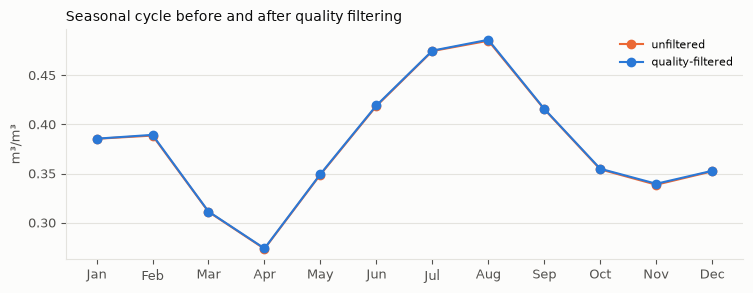

month          1      2      3      4      5      6      7      8      9      10     11     12
unfiltered  0.385  0.389  0.311  0.273  0.349  0.419  0.475  0.485  0.415  0.354  0.339  0.352
filtered    0.385  0.389  0.311  0.274  0.350  0.419  0.475  0.486  0.416  0.355  0.340  0.353
difference  0.000  0.001  0.000  0.000  0.001  0.001  0.000  0.001  0.000  0.001  0.001  0.001


In [5]:
unfiltered = (raw.groupby(["region", "date"])["soil_moisture_m3_m3"].mean()
                .rename("sm_unfiltered").reset_index())

def seasonal(frame, col):
    frame = frame.copy(); frame["month"] = frame["date"].dt.month
    return frame.groupby("month")[col].mean()

comp = pd.DataFrame({
    "unfiltered": seasonal(unfiltered, "sm_unfiltered"),
    "filtered": seasonal(daily_sm, "sm"),
})
comp["difference"] = (comp["filtered"] - comp["unfiltered"]).round(3)

fig, ax = plt.subplots(figsize=(7.6, 3))
ax.plot(comp.index, comp["unfiltered"], marker="o", color=ORANGE, label="unfiltered")
ax.plot(comp.index, comp["filtered"], marker="o", color=BLUE, label="quality-filtered")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.set_ylabel("m³/m³"); ax.grid(axis="y"); ax.set_axisbelow(True)
ax.set_title("Seasonal cycle before and after quality filtering", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
print(comp.round(3).T.to_string())

**What we actually observe:** the two curves sit on top of each other and the trend
table reports the same slope twice, with identical sample sizes. The extra flag steps
removed zero records. That is the expected outcome given the upstream filtering, and it
is reported rather than hidden — the alternative (quietly presenting a "quality-filtered"
series that was never filtered here) would misrepresent the provenance.

In [6]:
def trend_stats(frame, col, label):
    out = []
    for region, g in frame.groupby("region"):
        g = g.dropna(subset=[col]).sort_values("date")
        if len(g) < 60:
            continue
        x = (g["date"] - g["date"].min()).dt.days / 365.25
        slope, intercept = np.polyfit(x, g[col], 1)
        resid = g[col] - (slope * x + intercept)
        se = np.sqrt((resid ** 2).sum() / (len(g) - 2) / ((x - x.mean()) ** 2).sum())
        out.append({"region": pretty(region), "series": label,
                    "slope m3/m3 per year": round(slope, 4),
                    "95% CI low": round(slope - 1.96 * se, 4),
                    "95% CI high": round(slope + 1.96 * se, 4),
                    "n": len(g)})
    return pd.DataFrame(out)

trends = pd.concat([trend_stats(unfiltered, "sm_unfiltered", "unfiltered"),
                    trend_stats(daily_sm, "sm", "filtered")])
trends.to_csv(OUT / "soil_moisture_trends.csv", index=False)
piv = trends.pivot(index="region", columns="series", values="slope m3/m3 per year")
print(piv.round(4).to_string())

series                filtered  unfiltered
region                                    
Central Dhaka          -0.0180     -0.0188
North Rangpur          -0.0132     -0.0129
Northeast Sylhet       -0.0207     -0.0210
Northwest Rajshahi     -0.0049     -0.0049
South Barishal         -0.0172     -0.0179
Southeast Chattogram   -0.0374     -0.0382
Southwest Khulna       -0.0135     -0.0133

## 4. Drought state: where does today sit in this region's history?

A percentile is more useful than an absolute value because 0.30 m³/m³ is normal in
Rajshahi and dry in Khulna.

In [7]:
sm_series = daily_sm.copy()
sm_series["month"] = sm_series["date"].dt.month
sm_series["pct"] = sm_series.groupby(["region", "month"])["sm"].rank(pct=True) * 100

def classify(p):
    if not np.isfinite(p): return "no data"
    if p < 10: return "very dry"
    if p < 25: return "dry"
    if p > 90: return "very wet"
    if p > 75: return "wet"
    return "normal"

sm_series["state"] = sm_series["pct"].apply(classify)
latest = sm_series.sort_values("date").groupby("region").tail(30)
summary = (latest.groupby("region")
           .agg(last_date=("date", "max"),
                latest_sm=("sm", "last"),
                latest_pct=("pct", "last"),
                state=("state", "last"),
                days_observed=("sm", "count"))
           .reset_index())
summary["region"] = summary["region"].map(pretty)
summary.to_csv(OUT / "soil_moisture_state.csv", index=False)
summary

,region,last_date,latest_sm,latest_pct,state,days_observed
0,Central Dhaka,2026-11-08,0.391418,33.333333,normal,30
1,North Rangpur,2026-11-08,0.176398,1.136364,very dry,30
2,Northeast Sylhet,2026-11-08,0.331304,45.333333,normal,30
3,Northwest Rajshahi,2026-11-08,0.264824,10.227273,dry,30
4,South Barishal,2026-11-08,0.267235,14.606742,dry,30
5,Southeast Chattogram,2026-11-08,0.200824,35.294118,normal,30
6,Southwest Khulna,2026-11-08,0.448951,33.707865,normal,30


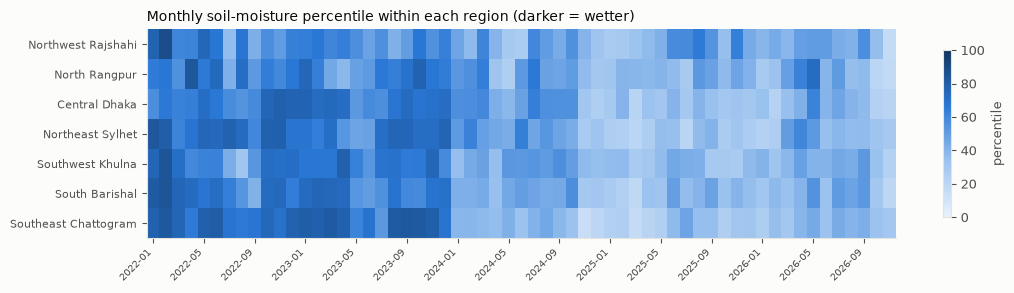

In [8]:
sm_series["period"] = sm_series["date"].dt.to_period("M").astype(str)
pivot = sm_series.pivot_table(index="region", columns="period",
                               values="pct", aggfunc="mean").reindex(regions)
pivot.columns = [str(c) for c in pivot.columns]

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(pivot.values, cmap=SEQ, aspect="auto", vmin=0, vmax=100)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([pretty(r) for r in pivot.index], fontsize=8)
step = max(1, len(pivot.columns) // 14)
ax.set_xticks(range(0, len(pivot.columns), step))
ax.set_xticklabels(pivot.columns[::step], rotation=45, ha="right", fontsize=7)
ax.set_title("Monthly soil-moisture percentile within each region (darker = wetter)", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8, label="percentile")
fig.tight_layout(); plt.show()

## 5. What a monitoring product may and may not claim

**May claim:** a regional wetness percentile, updated as retrievals arrive, with the
number of observations behind it; a comparison of this month with the same month in
previous years.

**May not claim:** field-level soil moisture, root-zone water, or irrigation advice for a
specific plot. The product is 9 km, the retrieval depth is the top ~5 cm, and roughly
three days in five have no value at all.

**Watch the trend test.** The confidence intervals assume independent samples, but soil
moisture is autocorrelated, so the true interval is wider. Treat a slope as a direction,
not a measurement, and never extrapolate it.